# Module 3 · Stationary distributions, absorption, and hitting times
**Applied Stochastic Processes: Modeling, Simulation, and AI**

Practical question: **What does a fitted chain predict in the long run, and how long might we wait for the first high-rental day?**

Guided work: about 40–50 minutes. Exercises: about 25–35 minutes. This is **Concept Lab 2, Part A (week 3)**; Module 4 supplies Part B in week 4. This is not a new project.

You will distinguish invariant distributions from endpoint limits and path averages, derive and simulate first-passage quantities, handle finite simulation horizons honestly, and solve a small absorbing chain. Probability and linear algebra ideas are explained before code.

[Course home](../index.html) · [Interactive lesson](../modules/module03.html) · [Project guide](../project-guide.html) · [Data provenance](../data/PROVENANCE.md)

Use **Restart Kernel and Run All** from the course root or `notebooks/`. No download, account, API key, or Python web server is required. Keep exercise answers in your own copy.

## 1. Preserve the model and the data boundary
As in Module 2, $X_t$ is **completed bike rentals** on calendar day $t$ and $Y_t=1\{X_t>4000\}$. Exactly 4,000 rentals is state $0$. The threshold is a reporting scenario, not measured fleet capacity. Rentals do not measure unmet requests, unique bikes, or latent demand.

The state order is $[0,1]$ and **rows are origins, columns destinations**. For a first-order, time-homogeneous model,

$$P=\begin{pmatrix}1-a&a\\b&1-b\end{pmatrix},\qquad \nu_n=\nu_0P^n.$$

Fit only January–August 2011. The already-inspected September–December period remains a **development holdout**. It cannot now support a claim of pristine final validation.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 6231
plt.rcParams.update({"figure.figsize": (10, 3.6), "font.size": 11})

The bundled UCI Bike Sharing observations (Fanaee-T, 2013; [DOI 10.24432/C5W894](https://doi.org/10.24432/C5W894), **CC BY 4.0**) contain 365 daily records from Capital Bikeshare in Washington, D.C. We verify the provenance hash and complete calendar before analyzing a single observed path. No additional observations are introduced.

In [2]:
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/bike_daily_2011.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the downloaded course folder.")
csv_path = ROOT / "data/bike_daily_2011.csv"
source = json.loads((ROOT / "data/source_metadata.json").read_text())
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == source["sample_sha256"]
bike = pd.read_csv(csv_path, parse_dates=["dteday"])
assert bike["dteday"].tolist() == pd.date_range("2011-01-01", "2011-12-31").tolist()
assert bike["cnt"].notna().all() and bike["cnt"].ge(0).all()
assert np.equal(bike["cnt"], np.floor(bike["cnt"])).all()
THRESHOLD, SPLIT_DATE = 4000, pd.Timestamp("2011-09-01")
bike["y"] = (bike["cnt"] > THRESHOLD).astype(int)

In [3]:
train = bike.loc[bike["dteday"] < SPLIT_DATE].copy()
later = bike.loc[bike["dteday"] >= SPLIT_DATE].copy()
y_train, y_all = train["y"].to_numpy(), bike["y"].to_numpy()
N = np.zeros((2, 2), dtype=int)
np.add.at(N, (y_train[:-1], y_train[1:]), 1)
assert np.array_equal(N, [[114, 20], [19, 89]]) and N.sum() == 242
assert (len(train), len(later), y_train.sum()) == (243, 122, 109)
P_hat = N / N.sum(axis=1, keepdims=True)
a, b = P_hat[0, 1], P_hat[1, 0]
P_demo = np.array([[0.8, 0.2], [0.3, 0.7]])  # illustrative scenario
print("Fitted using within-training transitions only:")
display(pd.DataFrame(P_hat, index=["origin 0", "origin 1"], columns=["to 0", "to 1"]))

Fitted using within-training transitions only:


,to 0,to 1
origin 0,0.850746,0.149254
origin 1,0.175926,0.824074


## 2. A stationary distribution is an invariant probability law
A row probability vector $\pi$ is **stationary** when

$$\pi P=\pi,\qquad \pi_0+\pi_1=1,\quad \pi_i\ge0.$$

If $Y_0\sim\pi$, every $Y_n$ has law $\pi$. A particular path still changes states. Stationarity of the marginal law does not mean a constant path.

For two states, the first equation reduces to $\pi_0a=\pi_1b$: average probability flowing from $0$ to $1$ balances flow back. When $a+b>0$,

$$\boxed{\pi=\left[\frac{b}{a+b},\frac{a}{a+b}\right]}.$$

If $a=b=0$, $P=I$: **every** probability vector is stationary. A solver must not divide by zero and invent uniqueness. A finite irreducible chain (every state can reach every other) has a unique stationary distribution. Aperiodicity is additionally sufficient for $\nu_0P^n\to\pi$ from every initial law.

In [4]:
def validate_transition(P):
    P = np.asarray(P, dtype=float)
    if P.ndim != 2 or P.shape[0] != P.shape[1]:
        raise ValueError("P must be square")
    if not np.isfinite(P).all() or (P < 0).any() or not np.allclose(P.sum(1), 1):
        raise ValueError("P must be finite, nonnegative, and row stochastic")
    return P


def stationary_two(P):
    P = validate_transition(P)
    if P.shape != (2, 2) or P[0, 1] + P[1, 0] == 0:
        raise ValueError("Need two states and a+b>0; identity has no unique pi")
    a, b = P[0, 1], P[1, 0]
    return np.array([b, a]) / (a + b)

In [5]:
pi_hat, pi_demo = stationary_two(P_hat), stationary_two(P_demo)
for matrix, pi in [(P_hat, pi_hat), (P_demo, pi_demo)]:
    assert np.allclose(pi @ matrix, pi)
    assert np.isclose(pi.sum(), 1) and (pi >= 0).all()
assert np.allclose(pi_demo, [0.6, 0.4])
assert np.isclose(pi_hat[1], 0.4589885252868678)
comparison = pd.Series({"Fitted stationary pi[1]": pi_hat[1],
                        "Observed Jan–Aug fraction": train["y"].mean(),
                        "Observed Sep–Dec fraction": later["y"].mean()})
monthly = bike.groupby(bike["dteday"].dt.month)["y"].mean()
display(comparison.to_frame("state-1 fraction"))

,state-1 fraction
Fitted stationary pi[1],0.458989
Observed Jan–Aug fraction,0.448560
Observed Sep–Dec fraction,0.393443


### A stationary model need not describe a stationary dataset
The fitted invariant high-state probability is about **0.4590**, compared with observed fractions **0.4486** in training and **0.3934** later. The training fraction counts days, whereas $\widehat P$ normalizes transition counts; the finite-path boundary matters, so these values need not coincide.

The monthly plot is a diagnostic of the homogeneous stationary approximation. The calendar pattern motivates investigating season, weather, growth, and omitted states. It neither establishes the source of a change nor proves a stationary model is adequate. The algebraic existence of $\pi$ for $\widehat P$ does not guarantee stable real-world rental behavior.

**Predict:** Would generating more paths from $\widehat P$ resolve disagreement with observed monthly fractions?

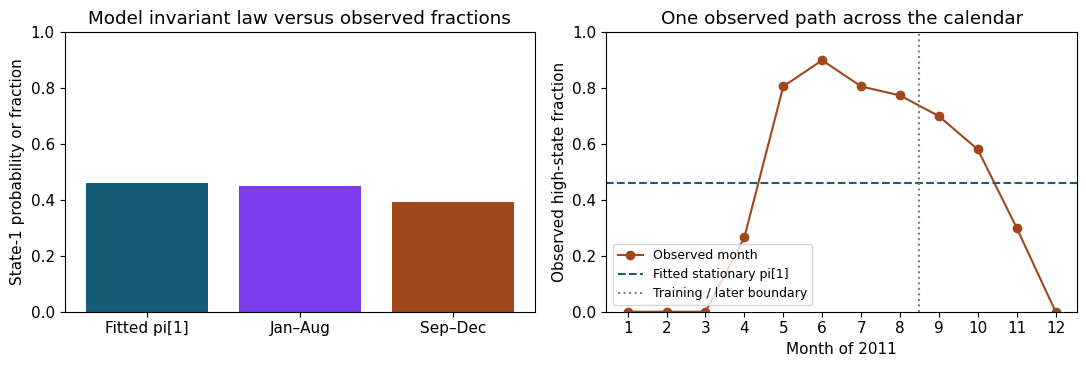

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(["Fitted pi[1]", "Jan–Aug", "Sep–Dec"], comparison.values,
            color=["#155e75", "#7c3aed", "#a0471c"])
axes[0].set(ylabel="State-1 probability or fraction", ylim=(0, 1),
            title="Model invariant law versus observed fractions")
axes[1].plot(monthly.index, monthly.values, "o-", color="#a0471c", label="Observed month")
axes[1].axhline(pi_hat[1], color="#155e75", ls="--", label="Fitted stationary pi[1]")
axes[1].axvline(8.5, color="gray", ls=":", label="Training / later boundary")
axes[1].set(xlabel="Month of 2011", ylabel="Observed high-state fraction",
            xticks=np.arange(1, 13), ylim=(0, 1), title="One observed path across the calendar")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

## 3. Three different quantities: law, ensemble, and path average
1. **Exact endpoint probability:** $q_n=(e_iP^n)_1$; no random simulation is needed.
2. **Ensemble endpoint estimate:** $R^{-1}\sum_{r=1}^R Y_n^{(r)}$ across independent simulated paths. At fixed $n$, its Monte Carlo standard error is $\sqrt{q_n(1-q_n)/R}$.
3. **One-path occupation fraction:** $\overline Y_N=N^{-1}\sum_{n=1}^N Y_n$. Successive states are dependent; the iid Bernoulli standard-error formula generally does **not** apply to this average.

For a finite irreducible chain, $\overline Y_N\to\pi_1$ almost surely, including periodic chains. This time-average conclusion is different from convergence of the endpoint law. For our two-state model,

$$q_n=\pi_1+(i-\pi_1)(1-a-b)^n,$$

so a negative $1-a-b$ produces oscillations. The browser and notebook use $P_{\rm demo}$, initial state $1$, horizon $100$, $R=1000$, seed $6231$. They use different random generators; equal seeds do not imply identical paths.

In [7]:
def simulate_chain(P, initial, horizon, reps, seed=SEED):
    P = validate_transition(P)
    if P.shape != (2, 2) or initial not in (0, 1):
        raise ValueError("This simulator needs two states and initial 0 or 1")
    if not isinstance(horizon, (int, np.integer)) or horizon < 0:
        raise ValueError("horizon must be a nonnegative integer")
    if not isinstance(reps, (int, np.integer)) or reps < 1:
        raise ValueError("reps must be a positive integer")
    paths = np.empty((reps, horizon + 1), dtype=int)
    paths[:, 0] = initial
    rng = np.random.default_rng(seed)
    for n in range(1, horizon + 1):
        paths[:, n] = rng.random(reps) < P[paths[:, n - 1], 1]
    return paths

In [8]:
HORIZON, REPS, INITIAL = 100, 1000, 1
paths_demo = simulate_chain(P_demo, INITIAL, HORIZON, REPS)
steps = np.arange(HORIZON + 1)
q_demo = np.array([np.linalg.matrix_power(P_demo, int(n))[INITIAL, 1] for n in steps])
ensemble = paths_demo.mean(axis=0)
occupation = np.cumsum(paths_demo[0, 1:]) / np.arange(1, HORIZON + 1)
assert np.allclose(q_demo, pi_demo[1] + (INITIAL - pi_demo[1]) * 0.5 ** steps)
assert np.array_equal(paths_demo, simulate_chain(P_demo, INITIAL, HORIZON, REPS))
assert np.all(simulate_chain(np.eye(2), 1, 5, 4) == 1)
assert simulate_chain(P_demo, 1, 0, 4).shape == (4, 1)
endpoint_mcse = np.sqrt(q_demo[-1] * (1 - q_demo[-1]) / REPS)
assert abs(ensemble[-1] - q_demo[-1]) < 5 * endpoint_mcse
print(f"Day 100: exact={q_demo[-1]:.4f}, ensemble={ensemble[-1]:.4f}, MCSE={endpoint_mcse:.4f}")

Day 100: exact=0.4000, ensemble=0.3820, MCSE=0.0155


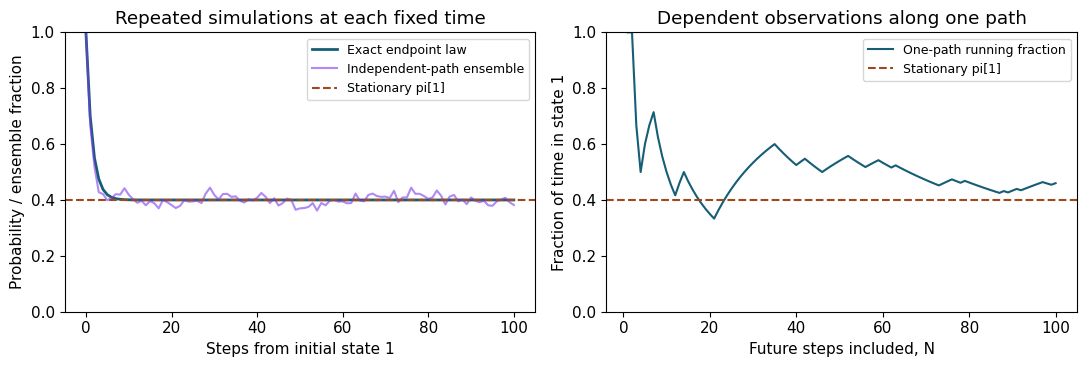

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(steps, q_demo, color="#155e75", lw=2, label="Exact endpoint law")
axes[0].plot(steps, ensemble, color="#7c3aed", alpha=0.6, label="Independent-path ensemble")
axes[0].axhline(pi_demo[1], color="#a0471c", ls="--", label="Stationary pi[1]")
axes[0].set(xlabel="Steps from initial state 1", ylabel="Probability / ensemble fraction",
            ylim=(0, 1), title="Repeated simulations at each fixed time")
axes[1].plot(steps[1:], occupation, color="#155e75", label="One-path running fraction")
axes[1].axhline(pi_demo[1], color="#a0471c", ls="--", label="Stationary pi[1]")
axes[1].set(xlabel="Future steps included, N", ylabel="Fraction of time in state 1",
            ylim=(0, 1), title="Dependent observations along one path")
for ax in axes:
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

### A counterexample prevents an overgeneralization
For the alternating chain $P_{\rm alt}=\begin{pmatrix}0&1\\1&0\end{pmatrix}$, the unique stationary distribution is $[1/2,1/2]$. Starting at state $0$, its endpoint probability alternates $0,1,0,1,\ldots$ and **never converges**. Its period is two. Yet its time occupation fraction converges to $1/2$.

If it instead starts with law $[1/2,1/2]$, its marginal law is invariant at every time, although every individual path alternates. For the identity chain, the initial state never changes, and the limiting law depends on the initial law: there is no unique stationary distribution.

**Predict before running:** Which assertion fails: “stationary exists,” “stationary is unique,” or “every initial endpoint law converges”?

In [10]:
P_alt = np.array([[0.0, 1.0], [1.0, 0.0]])
alt_steps = np.arange(21)
alt_path = simulate_chain(P_alt, 0, 20, 1)[0]
alt_exact = np.array([np.linalg.matrix_power(P_alt, int(n))[0, 1] for n in alt_steps])
alt_occupation = np.cumsum(alt_path[1:]) / alt_steps[1:]
assert np.array_equal(alt_path, alt_steps % 2)
assert np.array_equal(alt_exact, alt_path)
assert np.allclose(stationary_two(P_alt), [0.5, 0.5])
assert np.allclose(np.array([0.5, 0.5]) @ P_alt, [0.5, 0.5])
try:
    stationary_two(np.eye(2))
except ValueError as error:
    print("Expected nonunique case:", error)
else:
    raise AssertionError("Identity must be reported as nonunique")

Expected nonunique case: Need two states and a+b>0; identity has no unique pi


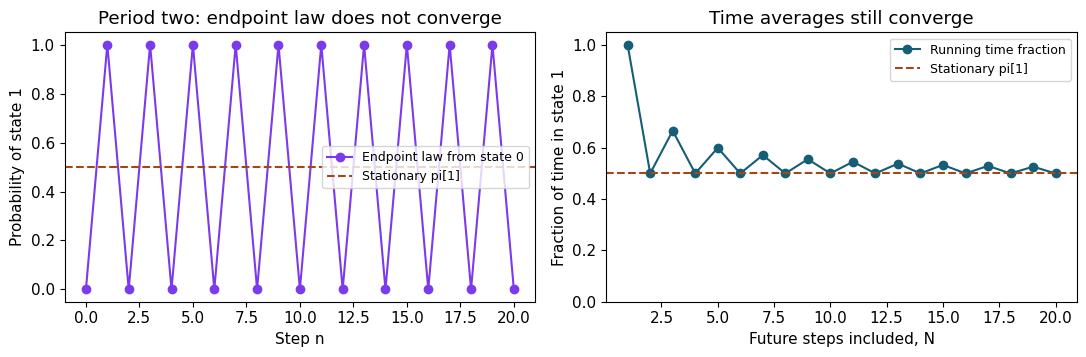

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].plot(alt_steps, alt_exact, "o-", color="#7c3aed", label="Endpoint law from state 0")
axes[0].axhline(0.5, color="#a0471c", ls="--", label="Stationary pi[1]")
axes[0].set(xlabel="Step n", ylabel="Probability of state 1", ylim=(-0.05, 1.05),
            title="Period two: endpoint law does not converge")
axes[1].plot(alt_steps[1:], alt_occupation, "o-", color="#155e75", label="Running time fraction")
axes[1].axhline(0.5, color="#a0471c", ls="--", label="Stationary pi[1]")
axes[1].set(xlabel="Future steps included, N", ylabel="Fraction of time in state 1",
            ylim=(0, 1.05), title="Time averages still converge")
for ax in axes:
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 4. First passage asks “ever by then,” not “there at the endpoint”
For a target set $A$, define the hitting time

$$T_A=\inf\{n\ge0:Y_n\in A\},\qquad \inf\varnothing=\infty.$$

Starting in $A$ gives $T_A=0$. The **first return time** $T_A^+=\inf\{n\ge1:Y_n\in A\}$ is a different quantity. We use first passage to $A=\{1\}$ from state $0$ below.

To find a first visit, we may replace the target's row with an absorbing row: $P^{\rm hit}=\begin{pmatrix}1-a&a\\0&1\end{pmatrix}$. This preserves the first-hit event and time. It does **not** claim that observed bike rentals stay high forever. The original fitted chain can return to state $0$ after a high day.

Until its first hit, this two-state chain remains in state $0$, trying again each day with probability $a$. Thus, for $a>0$,

$$P_0(T_1=k)=(1-a)^{k-1}a,\quad k=1,2,\ldots,$$
$$P_0(T_1>H)=(1-a)^H,\quad P_0(T_1\le H)=1-(1-a)^H,$$
$$E_0[T_1]=\sum_{n=0}^{\infty}P_0(T_1>n)=\frac1a.$$

For the fitted bike matrix, $a=20/134$, so the model's mean wait is **6.7 days**. This is conditional on the fitted homogeneous model. It is not an observed average or a guarantee for the next calendar period. At horizon $H$, the hit probability generally exceeds $(P^H)_{01}$ because paths can visit state $1$ and later leave.

In [12]:
H_HIT = 30
P_hit = P_hat.copy()
P_hit[1] = [0.0, 1.0]
hit_steps = np.arange(H_HIT + 1)
survival = (1 - a) ** hit_steps
hit_probability = 1 - survival[-1]
full_mean = 1 / a
restricted_mean = np.sum(survival[:-1])
assert np.isclose(restricted_mean, (1 - (1 - a) ** H_HIT) / a)
assert np.isclose(np.linalg.matrix_power(P_hit, H_HIT)[0, 1], hit_probability)
assert hit_probability > np.linalg.matrix_power(P_hat, H_HIT)[0, 1]
assert np.isclose(full_mean, 6.7)
print(f"H={H_HIT}: P(hit by H)={hit_probability:.6f}; E[T]={full_mean:.6f} days")

H=30: P(hit by H)=0.992166; E[T]=6.700000 days


### Keep misses visible: finite simulations are right censored
A run ending after $H$ transitions cannot reveal a wait longer than $H$. Retain **both** $D=1\{T_1\le H\}$ and $C=\min(T_1,H)$. If a hit occurs exactly at $H$, then $C=H,D=1$; if no hit occurs by $H$, then $C=H,D=0$.

The hit-only average estimates $E[T_1\mid T_1\le H]$, favoring short waits. The average of the capped values estimates a different, valid quantity: the **restricted mean**

$$E[\min(T_1,H)]=\sum_{n=0}^{H-1}P(T_1>n)=\frac{1-(1-a)^H}{a}.$$

Neither average should be labeled the full $E[T_1]$. Do not code misses as zero, discard them silently, or assume a horizon cap is an actual hit.

In [13]:
def first_hit_summary(paths, target=1):
    """Return hit indicator and min(T,H), including a possible hit at time zero."""
    paths = np.asarray(paths)
    if paths.ndim != 2 or paths.shape[1] < 1:
        raise ValueError("paths needs an origin column")
    visited = paths == target
    hit = visited.any(axis=1)
    capped = np.where(hit, visited.argmax(axis=1), paths.shape[1] - 1)
    return hit, capped

hit_paths = simulate_chain(P_hat, 0, H_HIT, REPS)
hit, capped = first_hit_summary(hit_paths)
assert first_hit_summary(np.array([[1, 0, 0]]))[1][0] == 0
assert np.array_equal(first_hit_summary(np.array([[0, 0, 1], [0, 0, 0]]))[0], [True, False])
assert np.array_equal(first_hit_summary(np.array([[0, 0, 1], [0, 0, 0]]))[1], [2, 2])

In [14]:
hit_only_exact = np.sum(hit_steps[1:] * a * (1-a) ** hit_steps[:-1]) / hit_probability
hit_report = pd.DataFrame({"quantity": ["Hit fraction by H", "Tail fraction beyond H",
    "Restricted mean min(T,H), days", "Hit-only mean, days", "Full mean T, days"],
    "exact under fitted model": [hit_probability, survival[-1], restricted_mean,
                                 hit_only_exact, full_mean],
    "simulation": [hit.mean(), 1-hit.mean(), capped.mean(),
                   capped[hit].mean() if hit.any() else np.nan, np.nan]})
display(hit_report.round(6))
hit_mcse = np.sqrt(hit_probability * (1-hit_probability) / REPS)
assert abs(hit.mean() - hit_probability) < 5 * hit_mcse
empirical_survival = np.array([np.mean((~hit) | (capped > n)) for n in hit_steps])
assert np.isclose(empirical_survival[-1], 1 - hit.mean())
assert np.isclose(empirical_survival[:-1].sum(), capped.mean())

,quantity,exact under fitted model,simulation
0,Hit fraction by H,0.992166,0.995000
1,Tail fraction beyond H,0.007834,0.005000
2,"Restricted mean min(T,H), days",6.647510,6.478000
3,"Hit-only mean, days",6.463114,6.359799
4,"Full mean T, days",6.700000,NaN


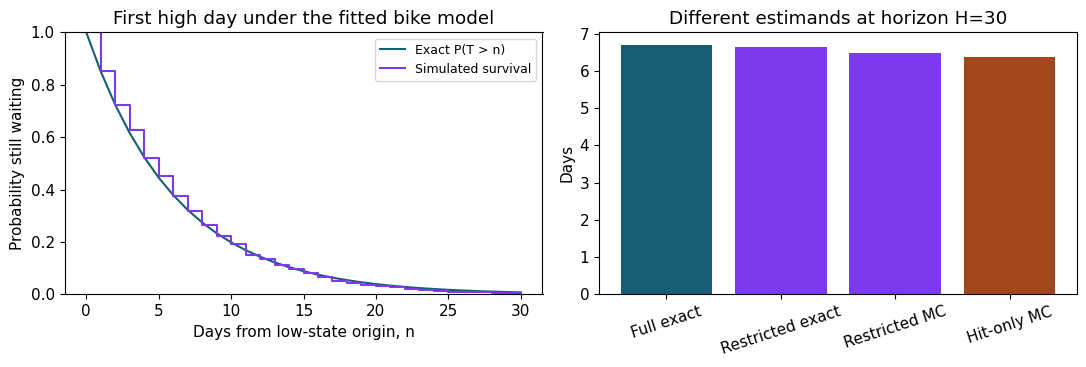

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(hit_steps, survival, color="#155e75", label="Exact P(T > n)")
axes[0].step(hit_steps, empirical_survival, where="post", color="#7c3aed", label="Simulated survival")
axes[0].set(xlabel="Days from low-state origin, n", ylabel="Probability still waiting",
            ylim=(0, 1), title="First high day under the fitted bike model")
axes[0].legend(fontsize=9)
axes[1].bar(["Full exact", "Restricted exact", "Restricted MC", "Hit-only MC"],
            [full_mean, restricted_mean, capped.mean(), capped[hit].mean()],
            color=["#155e75", "#7c3aed", "#7c3aed", "#a0471c"])
axes[1].set(ylabel="Days", title=f"Different estimands at horizon H={H_HIT}")
axes[1].tick_params(axis="x", rotation=18)
fig.tight_layout()
plt.show()

## 5. Compare first-passage predictions with observed windows
Freeze the training matrix and set **$H=7$ before this comparison**. Consider candidate origins from August 31 onward, keep only origins in state $0$, and require all next seven calendar days to be observed by December 31. For each origin, ask whether a high day appears within those seven future days and record $\min(T_1,7)$.

Requiring a complete window avoids **dataset-end censoring** of these fixed-horizon quantities. A no-hit window still only tells us $T_1>7$; it does not reveal the full wait. August 31 is eligible by date but in state $1$, so it will not be selected. Overlapping windows from one time series are dependent; no iid calibration standard error is justified.

In [16]:
def observed_hit_windows(states, dates, horizon=7, first_origin=242):
    if not isinstance(horizon, (int, np.integer)) or horizon < 1:
        raise ValueError("Use a positive whole-day horizon")
    origins = np.arange(first_origin, len(states) - horizon)
    origins = origins[states[origins] == 0]
    future = np.array([states[i+1:i+horizon+1] for i in origins])
    if not len(origins):
        raise ValueError("No eligible low-state origins with complete windows")
    hit = future.any(axis=1)
    capped = np.where(hit, future.argmax(axis=1) + 1, horizon)
    return pd.DataFrame({"origin_index": origins, "origin_date": dates.iloc[origins].to_numpy(),
        "window_end": dates.iloc[origins + horizon].to_numpy(),
        "hit_by_H": hit, "min_T_H": capped})

observed = observed_hit_windows(y_all, bike["dteday"], horizon=7)
H_OBS = 7

In [17]:
assert len(observed) == 67 and observed["hit_by_H"].sum() == 28
assert observed["min_T_H"].sum() == 334
assert observed.iloc[0]["origin_date"] == pd.Timestamp("2011-09-05")
assert observed.iloc[-1]["origin_date"] == pd.Timestamp("2011-12-24")
assert observed["window_end"].max() == pd.Timestamp("2011-12-31")
assert (observed["origin_index"] >= 242).all()
model_hit7 = 1 - (1 - a) ** H_OBS
model_restricted7 = model_hit7 / a
observed_report = pd.DataFrame({"Frozen fitted model": [model_hit7, model_restricted7],
    "Observed complete windows": [observed["hit_by_H"].mean(), observed["min_T_H"].mean()]},
    index=["P(hit within 7 days)", "Restricted mean min(T,7), days"])
display(observed_report.round(6))
display(observed.iloc[[0, -1]])

,Frozen fitted model,Observed complete windows
P(hit within 7 days),0.677448,0.417910
"Restricted mean min(T,7), days",4.538898,4.985075


,origin_index,origin_date,window_end,hit_by_H,min_T_H
0,247,2011-09-05,2011-09-12,True,5
66,357,2011-12-24,2011-12-31,False,7


Among **67 eligible low-state origins**, 28 have a high day within seven days: observed fraction **0.4179**, versus fitted-model probability **0.6774**. The observed restricted mean is **4.9851 days**, versus model value **4.5389 days**. These compare the same finite-horizon quantities.

The model predicts more frequent early hits than this later observed path supplies. This is a diagnostic of the frozen homogeneous approximation, not proof of a particular cause or a statistically significant difference. Overlap, season, and reuse of the development period matter. Inspecting several horizons or revising a model here further uses the same period for development; final project validation requires fresh observations or a prespecified design on observations not already used for model selection.

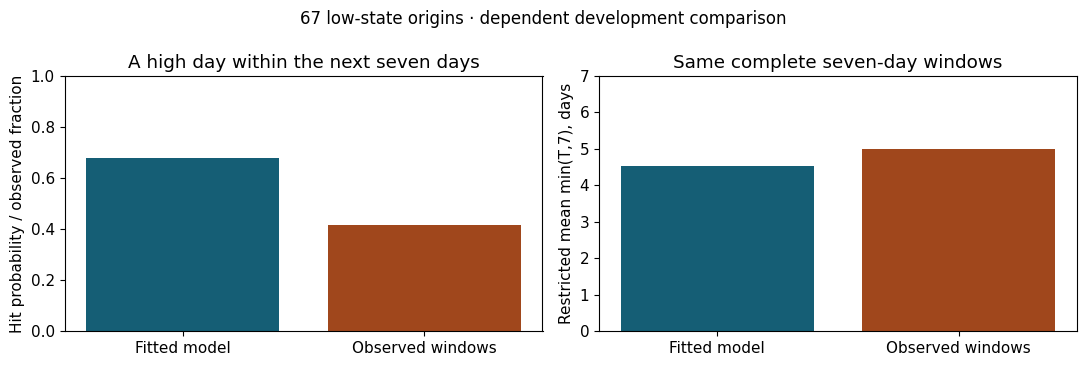

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].bar(["Fitted model", "Observed windows"], observed_report.iloc[0],
            color=["#155e75", "#a0471c"])
axes[0].set(ylabel="Hit probability / observed fraction", ylim=(0, 1),
            title="A high day within the next seven days")
axes[1].bar(["Fitted model", "Observed windows"], observed_report.iloc[1],
            color=["#155e75", "#a0471c"])
axes[1].set(ylabel="Restricted mean min(T,7), days", ylim=(0, 7),
            title="Same complete seven-day windows")
fig.suptitle("67 low-state origins · dependent development comparison", fontsize=12)
fig.tight_layout()
plt.show()

## 6. Absorption with two possible outcomes
First passage to “high” has only one absorbing target. To learn **which absorbing outcome** occurs, use a separate **synthetic operational escalation scenario** with states $0$ routine, $1$ strained, $2$ resolved, and $3$ escalated:

$$P_{\rm abs}=\begin{pmatrix}.6&.2&.2&0\\.1&.5&0&.4\\0&0&1&0\\0&0&0&1\end{pmatrix}
=\begin{pmatrix}Q&R\\0&I\end{pmatrix}.$$

All entries are **illustrative assumptions**, not estimates from bike-sharing data. A step is one assumed operational review interval; do not reinterpret it as a measured bike-rental day. States $2,3$ are absorbing: after the case is resolved or escalated, this model stops tracking it. Here $R$ denotes the exit-probability block, whereas `REPS` denotes the simulation count.

**Predict:** Which starting state has a higher chance of escalation, and which has a longer expected time to either outcome?

In [19]:
P_abs = np.array([[0.6, 0.2, 0.2, 0.0],
                  [0.1, 0.5, 0.0, 0.4],
                  [0.0, 0.0, 1.0, 0.0],
                  [0.0, 0.0, 0.0, 1.0]])
validate_transition(P_abs)
Q, R_exit = P_abs[:2, :2], P_abs[:2, 2:]
assert np.array_equal(P_abs[2:, 2:], np.eye(2))
assert np.allclose(Q.sum(1) + R_exit.sum(1), 1)
display(pd.DataFrame(P_abs, index=["routine", "strained", "resolved", "escalated"],
                     columns=["routine", "strained", "resolved", "escalated"]))

,routine,strained,resolved,escalated
routine,0.6,0.2,0.2,0.0
strained,0.1,0.5,0.0,0.4
resolved,0.0,0.0,1.0,0.0
escalated,0.0,0.0,0.0,1.0


### Expected visits, exit probabilities, and duration are related solves
Let $\tau=\inf\{n\ge0:Y_n\in\{2,3\}\}$. If $Q$ is transient, its spectral radius $\rho(Q)$ (largest eigenvalue magnitude) is less than one, $Q^n\to0$, and

$$F=\sum_{n=0}^{\infty}Q^n=(I-Q)^{-1},\qquad B=FR,\qquad t=F\mathbf1.$$

$F_{ij}$ is the expected number of visits to transient state $j$ **before absorption, including time zero**, from transient state $i$. $B_{ik}$ is the probability of eventual absorption in outcome $k$, and $t_i=E_i[\tau]$ counts transitions until absorption. Starting in an absorbing state instead gives $\tau=0$.

First-step conditioning gives $B=R+QB$ and $t=\mathbf1+Qt$. Solve these linear systems with `np.linalg.solve`; an explicit matrix inverse is unnecessary. Check transience first: an arbitrary proposed “transient block” may contain a closed nonabsorbing class, making the full expected time infinite for affected starting states.

In [20]:
def absorbing_quantities(Q, R_exit):
    Q, R_exit = np.asarray(Q, float), np.asarray(R_exit, float)
    if Q.ndim != 2 or Q.shape[0] != Q.shape[1] or R_exit.ndim != 2:
        raise ValueError("Q must be square and R_exit a matrix")
    if R_exit.shape[0] != len(Q):
        raise ValueError("Q and R_exit need the same number of origin rows")
    joined = np.column_stack([Q, R_exit])
    if (joined < 0).any() or not np.isfinite(joined).all() or not np.allclose(joined.sum(1), 1):
        raise ValueError("Transient and exit rows must be probabilities")
    rho = float(np.max(np.abs(np.linalg.eigvals(Q))))
    if rho >= 1 - 1e-12:
        raise ValueError("Q is not safely transient; do not report a finite all-state mean")
    A = np.eye(len(Q)) - Q
    F = np.linalg.solve(A, np.eye(len(Q)))
    return F, np.linalg.solve(A, R_exit), np.linalg.solve(A, np.ones(len(Q))), rho

In [21]:
F, B, t_abs, rho = absorbing_quantities(Q, R_exit)
assert np.allclose(F, [[25/9, 10/9], [5/9, 20/9]])
assert np.allclose(B, [[5/9, 4/9], [1/9, 8/9]])
assert np.allclose(t_abs, [35/9, 25/9])
assert np.allclose(F, np.eye(2) + Q @ F)
assert np.allclose(B, R_exit + Q @ B) and np.allclose(B.sum(1), 1)
assert np.allclose(t_abs, np.ones(2) + Q @ t_abs)
assert (F >= 0).all() and (B >= 0).all()
display(pd.DataFrame(B, index=["routine", "strained"], columns=["resolved", "escalated"]))
display(pd.Series(t_abs, index=["routine", "strained"], name="Expected review intervals"))
print(f"Spectral radius={rho:.3f}; equation residuals and probability checks passed.")

,resolved,escalated
routine,0.555556,0.444444
strained,0.111111,0.888889


routine     3.888889
strained    2.777778
Name: Expected review intervals, dtype: float64

Spectral radius=0.700; equation residuals and probability checks passed.


### Verify the scenario with independent simulations
The exact escalation probabilities are $4/9$ from routine and $8/9$ from strained. Mean times to either outcome are $35/9$ and $25/9$ review intervals, respectively. The longer mean from routine does not imply greater escalation risk.

Simulate through $H=30$ and keep the hit indicator. At finite $H$, compare observed outcome fractions with the **finite-horizon** probabilities in $P_{\rm abs}^{H}$, and compare capped durations with $\sum_{n=0}^{H-1}Q^n\mathbf1$. The exact eventual quantities $B,t$ are separate. Even if no simulated path remains unabsorbed, that does not prove the mathematical tail probability is zero.

In [22]:
def simulate_absorption(P, initial, horizon=30, reps=1000, seed=SEED):
    P = validate_transition(P)
    if P.shape != (4, 4) or initial not in range(4):
        raise ValueError("Use the four-state scenario and a valid origin")
    if horizon < 0 or reps < 1 or not isinstance(horizon, int) or not isinstance(reps, int):
        raise ValueError("Use a nonnegative integer horizon and positive integer reps")
    state = np.full(reps, initial, dtype=int)
    hit, capped = state >= 2, np.full(reps, 0 if initial >= 2 else horizon, dtype=int)
    rng, cdf = np.random.default_rng(seed), np.cumsum(P, axis=1)
    cdf[:, -1] = 1.0
    for n in range(1, horizon + 1):
        state = (rng.random(reps)[:, None] >= cdf[state]).sum(axis=1)
        new_hit = (~hit) & (state >= 2)
        capped[new_hit], hit = n, hit | new_hit
    return state, hit, capped

In [23]:
H_ABS = 30
abs_rows, abs_checks = [], []
for initial in (0, 1):
    state, absorbed, duration = simulate_absorption(P_abs, initial, H_ABS, REPS)
    finite = np.linalg.matrix_power(P_abs, H_ABS)[initial]
    restricted = sum((np.linalg.matrix_power(Q, n) @ np.ones(2))[initial] for n in range(H_ABS))
    abs_rows.append([finite[3], np.mean(state == 3), B[initial, 1], restricted,
                     duration.mean(), t_abs[initial], 1-absorbed.mean(), finite[:2].sum()])
    mcse = np.sqrt(finite[3] * (1 - finite[3]) / REPS)
    abs_checks.append(abs(np.mean(state == 3) - finite[3]) < 5 * mcse)
abs_report = pd.DataFrame(abs_rows, index=["routine", "strained"], columns=[
    "Escalated by H exact", "Escalated by H MC", "Eventual escalation exact",
    "Restricted mean exact", "Restricted mean MC", "Full mean exact", "Unabsorbed MC", "Unabsorbed exact"])
assert all(abs_checks)
display(abs_report.round(6))

,Escalated by H exact,Escalated by H MC,Eventual escalation exact,Restricted mean exact,Restricted mean MC,Full mean exact,Unabsorbed MC,Unabsorbed exact
routine,0.444424,0.410,0.444444,3.888789,3.676,3.888889,0.0,0.000030
strained,0.888879,0.895,0.888889,2.777728,2.708,2.777778,0.0,0.000015


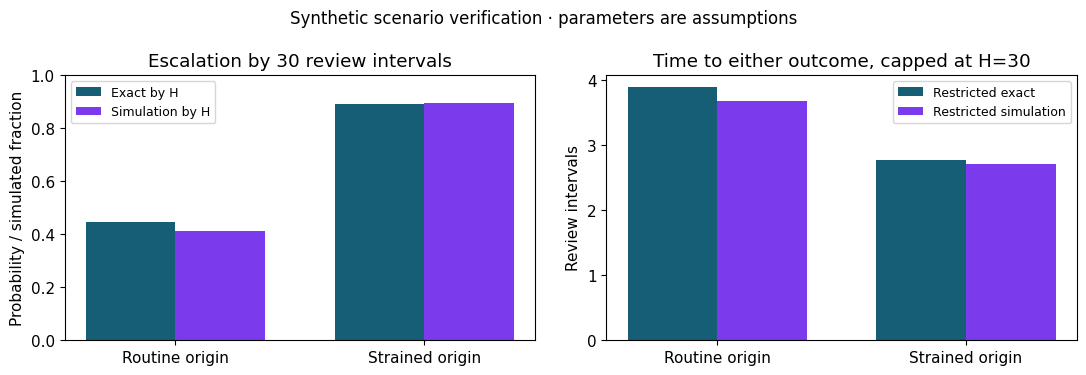

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(2)
axes[0].bar(x-0.18, abs_report["Escalated by H exact"], width=0.36, color="#155e75", label="Exact by H")
axes[0].bar(x+0.18, abs_report["Escalated by H MC"], width=0.36, color="#7c3aed", label="Simulation by H")
axes[0].set(ylabel="Probability / simulated fraction", ylim=(0, 1), title="Escalation by 30 review intervals")
axes[1].bar(x-0.18, abs_report["Restricted mean exact"], width=0.36, color="#155e75", label="Restricted exact")
axes[1].bar(x+0.18, abs_report["Restricted mean MC"], width=0.36, color="#7c3aed", label="Restricted simulation")
axes[1].set(ylabel="Review intervals", title="Time to either outcome, capped at H=30")
for ax in axes:
    ax.set_xticks(x, ["Routine origin", "Strained origin"])
    ax.legend(fontsize=9)
fig.suptitle("Synthetic scenario verification · parameters are assumptions", fontsize=12)
fig.tight_layout()
plt.show()

## 7. Know when a finite answer does not exist
If $a=0$ and we start at state $0$, target $1$ is unreachable: $T_1=\infty$ with probability one. For every finite $H$, hit probability is zero and $E[\min(T_1,H)]=H$; no finite full mean exists.

Likewise, declaring a row “transient” does not make it transient. With $Q=[1]$ and no exits, $I-Q$ is singular and the expected absorption time is infinite. In a larger reducible model, some origins may absorb while others can reach a closed class that avoids the target. Analyze reachability before promising a finite answer; the helper conservatively rejects a block that is not transient for all its rows. Its numerical tolerance can also reject nearly nontransient cases needing more careful analysis.

In [25]:
unreachable = np.eye(2)
never_hit, capped_never = first_hit_summary(simulate_chain(unreachable, 0, 30, 10))
assert not never_hit.any() and np.all(capped_never == 30)
try:
    absorbing_quantities(np.array([[1.0]]), np.array([[0.0, 0.0]]))
except ValueError as error:
    print("Expected nonabsorbing case:", error)
else:
    raise AssertionError("Do not return a finite mean for a closed nonabsorbing class")
state0, hit0, time0 = simulate_absorption(P_abs, 2, 0, 3)
assert hit0.all() and np.all(time0 == 0) and np.all(state0 == 2)
print("Unreachable target, zero-time hit, and closed-class checks passed.")

Expected nonabsorbing case: Q is not safely transient; do not report a finite all-state mean
Unreachable target, zero-time hit, and closed-class checks passed.


### Optional connection: return time is not first arrival from another state
For a **finite irreducible** chain, the mean first return time to state $i$, **starting in $i$**, is

$$E_i[T_i^+]=1/\pi_i.$$

For the fitted bike chain this gives about $1/0.4590=2.18$ days from a high day until the next high day, counting an immediate high day tomorrow as return time one. This does not contradict the 6.7-day mean first hit of high **from low**. The starting state and definition differ. Aperiodicity is not required for this mean-return identity.

## 8. AI may propose code; you must choose and verify the quantity
A generated eigenvector is not automatically a probability vector. With row-stochastic $P$, a stationary **row** law is a left eigenvector; `np.linalg.eig(P)` supplies right eigenvectors. Select the eigenvalue, orientation, normalization, and sign carefully, and verify $\pi P=\pi$, nonnegativity, and total mass one. Reducible chains may have multiple stationary laws.

A generated waiting-time average is not meaningful until misses, time-zero hits, horizon caps, and units are defined. A successful linear solve is not enough: verify the model assumptions and the equations $B=R+QB$, $t=\mathbf1+Qt$, and row sums of $B$. Report the prompt or tool used, which claims you accepted or rejected, and your independent checks. Using AI is optional and earns no credit by itself.

## Exercise 1 — Invariance, convergence, and occupation (6–8 minutes)
Use the **new** matrix $P_{\rm new}=\begin{pmatrix}.7&.3\\.2&.8\end{pmatrix}$.

1. Derive its stationary row distribution by balancing flow and normalizing. Verify the invariant equation.
2. From initial state $0$, compute the state-1 probability after one and ten steps. State why it converges and distinguish that probability from a one-path occupation fraction.
3. For the alternating and identity chains, state whether a stationary law exists, whether it is unique, and whether every initial endpoint law converges to one common stationary law. Explain why periodicity does not prevent the alternating chain's time average from converging.

In [26]:
# Your derivation, computations, and interpretation for Exercise 1.
# Keep this student notebook unanswered until you complete your own work.
pass

## Exercise 2 — A short horizon changes the estimand (6–8 minutes)
Using the frozen fitted bike matrix, start in state $0$ and compare horizons **$H=3$ and $H=14$**, each with 1,000 independent paths and seed 6231.

1. Retain hit indicators and capped times. Report hit fraction, tail fraction, hit-only mean, and restricted mean for each horizon; compare each defined quantity with its exact model value.
2. Explain why neither the hit-only nor capped average is an estimate of the full mean without further assumptions or tail treatment. Identify the full model mean and its units.
3. Demonstrate how to distinguish a hit exactly at $H$ from a miss, even though their capped times agree. Explain what changes if the origin is already in the target.

In [27]:
# Your horizon comparison and censoring audit for Exercise 2.
pass

## Exercise 3 — Audit the observed comparison (6–8 minutes)
Reconstruct the fixed **seven-day** comparison using only low-state origins at or after August 31 with complete future windows through December 31.

1. Report eligible origins, hits, first and last selected origin dates, observed hit fraction, and observed restricted mean. Show that no incomplete window was retained and that fitting still uses only the 242 within-training transitions.
2. Explain why August 31 is a candidate date but is not selected, why misses remain in the restricted mean, and why overlapping windows do not support an iid standard error.
3. Give one defensible modeling conclusion and one conclusion the comparison cannot support. Explain the development-holdout limitation. Optionally repeat for $H=3,14$, labeling the changed origin sets and further model development.

In [28]:
# Your chronology, window, and interpretation audit for Exercise 3.
pass

## Exercise 4 — Audit three AI proposals (7–10 minutes)
An AI assistant proposes:

```python
values, vectors = np.linalg.eig(P_hat)
pi = vectors[:, np.argmin(abs(values - 1))].real
pi = pi / pi.sum()                    # "stationary distribution"
mean_wait = capped[hit].mean()       # "unconditional mean first hit"
t = np.linalg.solve(np.eye(len(Q)) - Q, np.ones(len(Q)))  # "always finite"
```

1. Explain the distinct problem with each claim. Repair the stationary calculation and the reported waiting-time estimands without inventing unobserved hit times.
2. Provide a discriminating invariant-equation check on an asymmetric matrix; a symmetric-only check is insufficient. Use an unreachable target or a closed nonabsorbing class to challenge the “always finite” claim.
3. For the synthetic scenario, verify the equations for $F$, $B$, and $t$, and explain what their entries mean. Disclose any AI assistance and the checks you performed yourself.

In [29]:
# Your repaired calculations, counterexample, and independent checks for Exercise 4.
pass

## Checkpoint and project connection
Explain, without code, why a unique stationary distribution can coexist with oscillating endpoint laws; why a first-hit probability can exceed an endpoint probability; and why a small simulation discrepancy does not validate a model against real observations.

For Concept Lab 2, Part A, submit your four short exercise responses, selected output, and a brief record of verification and any AI use. Add one paragraph about how these ideas could inform the existing course project: name a state definition, an operationally meaningful target, the time unit, a finite-horizon estimand, and evidence needed for a homogeneous model. Do not start another project. Module 4 will complete Lab 2 and develop the next modeling tools.

The six figures above are generated from observed data or explicitly labeled synthetic scenarios. The environment report below supports reproducibility; all fixed seeds and numerical checks condition on the specified model.

In [30]:
print("Python", platform.python_version())
for package in ["numpy", "pandas", "matplotlib", "nbformat", "nbclient"]:
    print(package, metadata.version(package))
print("Seed:", SEED)
print("CSV SHA-256:", hashlib.sha256(csv_path.read_bytes()).hexdigest())
print("Completed: invariant-law, periodicity, hitting-time, window, and absorption checks.")

Python 3.10.9
numpy 1.24.2
pandas 2.0.0
matplotlib 3.7.1
nbformat 5.7.0
nbclient 0.5.13
Seed: 6231
CSV SHA-256: fb9790e24f07b237431b89c787a24ed8e97c365437a86f7161269df9452b2329
Completed: invariant-law, periodicity, hitting-time, window, and absorption checks.
